In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()

Saving Sample - Superstore.csv to Sample - Superstore.csv


In [ ]:
filename = next(iter(uploaded))

df = pd.read_csv(filename, encoding="latin1")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [ ]:
print("Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)

Dataset Shape: (9994, 21)

Missing Values:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

Duplicate Rows: 0

Data Types:
Row ID             int64
Order ID          object
Order Date        object
Ship Date         object
Ship Mode         object
Customer ID       object
Customer Name     object
Segment           object
Country           object
City              object
State             object
Postal Code        int64
Region            object
Product ID        object
Category          object
Sub-Category      object
Product Name      object
Sales            float64
Quantity           int64
Discount         float64
Profit       

In [ ]:
# STEP 3: DATA CLEANING

df_clean = df.copy()

# Convert date columns
df_clean["Order Date"] = pd.to_datetime(
    df_clean["Order Date"],
    errors="coerce"
)

df_clean["Ship Date"] = pd.to_datetime(
    df_clean["Ship Date"],
    errors="coerce"
)

print("Data cleaning completed!")
print("Dataset shape:", df_clean.shape)

print("\nDate column data types:")
print(df_clean[["Order Date", "Ship Date"]].dtypes)

Data cleaning completed!
Dataset shape: (9994, 21)

Date column data types:
Order Date    datetime64[ns]
Ship Date     datetime64[ns]
dtype: object


In [ ]:
# STEP 4: BUSINESS KPI ANALYSIS

total_sales = df_clean["Sales"].sum()
total_profit = df_clean["Profit"].sum()
total_orders = df_clean["Order ID"].nunique()
total_customers = df_clean["Customer ID"].nunique()

profit_margin = (total_profit / total_sales) * 100

print("====== BUSINESS KPI REPORT ======")
print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Customers: {total_customers:,}")
print(f"Profit Margin: {profit_margin:.2f}%")

====== BUSINESS KPI REPORT ======
Total Sales: $2,297,200.86
Total Profit: $286,397.02
Total Orders: 5,009
Total Customers: 793
Profit Margin: 12.47%


In [ ]:
# STEP 4: BUSINESS KPI ANALYSIS

total_sales = df_clean["Sales"].sum()
total_profit = df_clean["Profit"].sum()
total_orders = df_clean["Order ID"].nunique()
total_customers = df_clean["Customer ID"].nunique()

profit_margin = (total_profit / total_sales) * 100

print("===== BUSINESS KPI REPORT =====")
print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Customers: {total_customers:,}")
print(f"Profit Margin: {profit_margin:.2f}%")

===== BUSINESS KPI REPORT =====
Total Sales: $2,297,200.86
Total Profit: $286,397.02
Total Orders: 5,009
Total Customers: 793
Profit Margin: 12.47%


,Sales,Profit
Category,,
Furniture,741999.7953,18451.2728
Office Supplies,719047.0320,122490.8008
Technology,836154.0330,145454.9481


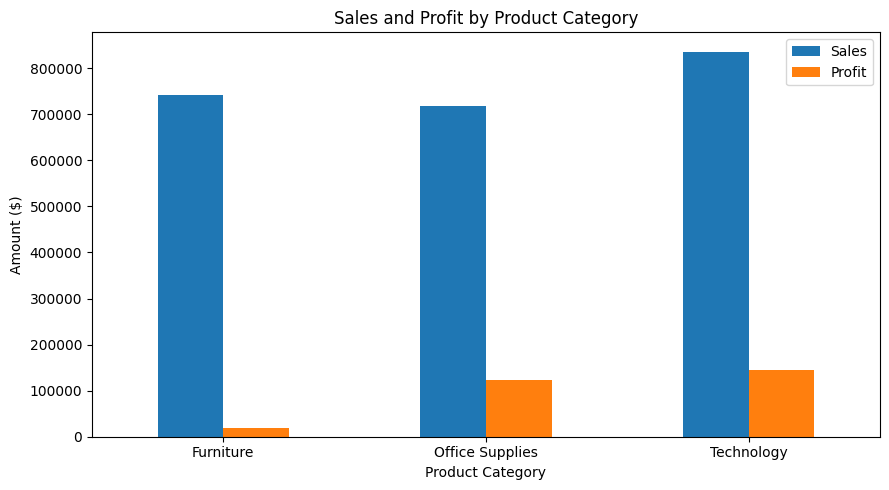

In [ ]:
# STEP 5: SALES AND PROFIT BY CATEGORY

category_sales = df_clean.groupby("Category")["Sales"].sum()
category_profit = df_clean.groupby("Category")["Profit"].sum()

category_summary = pd.DataFrame({
    "Sales": category_sales,
    "Profit": category_profit
})

display(category_summary)

category_summary.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Sales and Profit by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Amount ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Sales and Profit by Region:


,Sales,Profit
Region,,
Central,501239.89,39706.36
East,678781.24,91522.78
South,391721.90,46749.43
West,725457.82,108418.45


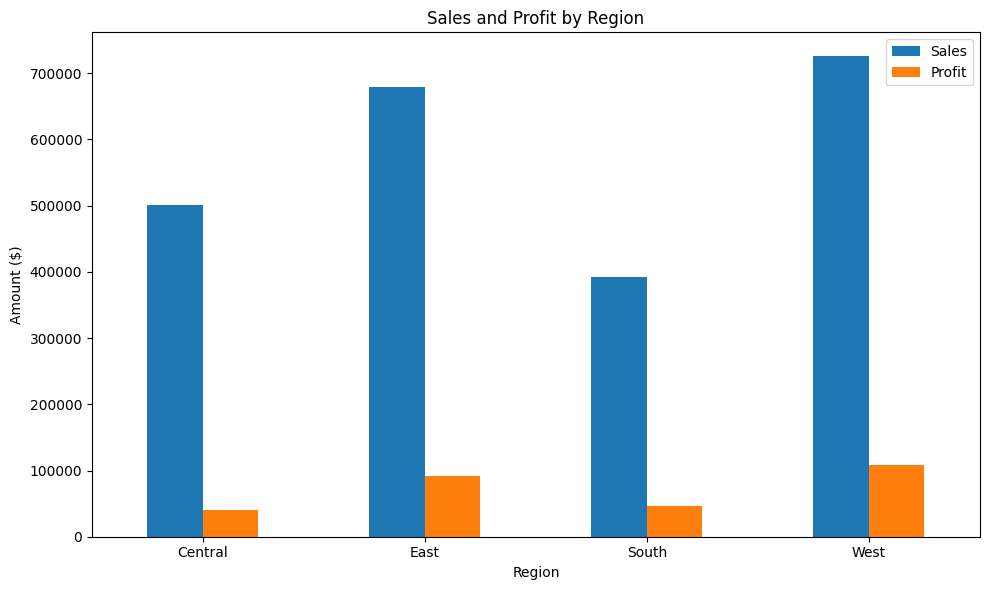

In [ ]:
import matplotlib.pyplot as plt

# Calculate sales and profit by region
region_summary = df_clean.groupby("Region").agg({
    "Sales": "sum",
    "Profit": "sum"
})

# Display results
print("Sales and Profit by Region:")
display(region_summary.round(2))

# Create the chart
region_summary.plot(kind="bar", figsize=(10, 6))

plt.title("Sales and Profit by Region")
plt.xlabel("Region")
plt.ylabel("Amount ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Monthly Sales:


,Sales
Year-Month,
2014-01,14236.90
2014-02,4519.89
2014-03,55691.01
2014-04,28295.34
2014-05,23648.29
2014-06,34595.13
2014-07,33946.39
2014-08,27909.47
2014-09,81777.35


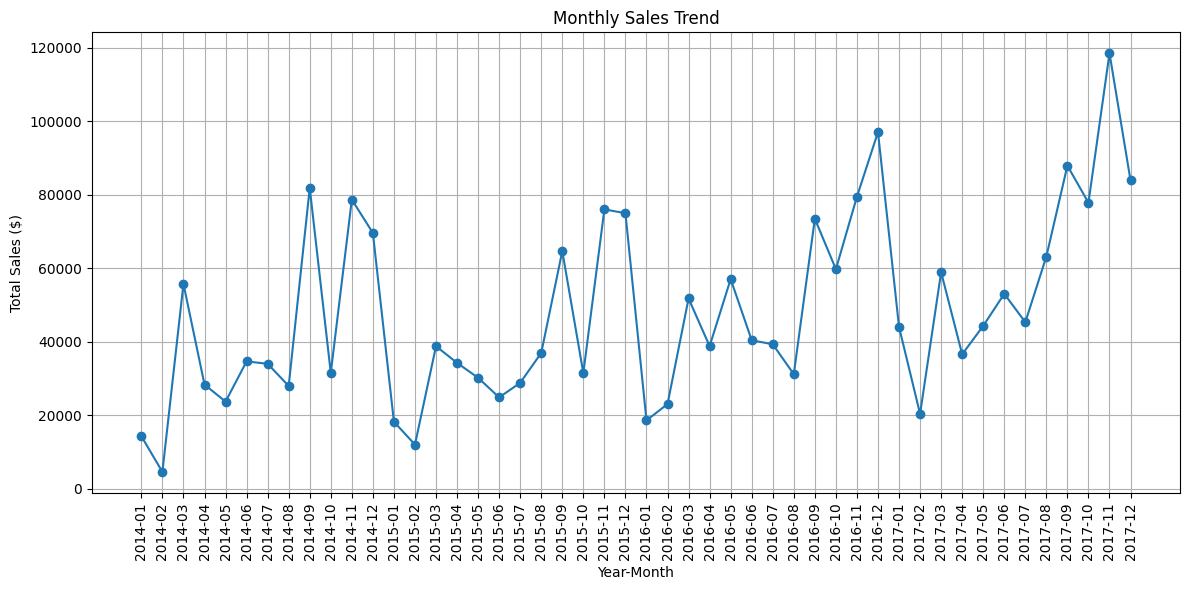

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df_clean["Year-Month"] = df_clean["Order Date"].dt.to_period("M")

monthly_sales = df_clean.groupby("Year-Month")["Sales"].sum()

print("Monthly Sales:")
display(monthly_sales.round(2))

plt.figure(figsize=(12, 6))
plt.plot(monthly_sales.index.astype(str), monthly_sales.values, marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Year-Month")
plt.ylabel("Total Sales ($)")
plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# STEP 7: HIGHEST AND LOWEST SALES MONTH

highest_month = monthly_sales.idxmax()
highest_sales = monthly_sales.max()

lowest_month = monthly_sales.idxmin()
lowest_sales = monthly_sales.min()

print("===== MONTHLY SALES ANALYSIS =====")
print(f"Highest Sales Month: {highest_month}")
print(f"Highest Sales Amount: ${highest_sales:,.2f}")

print(f"\nLowest Sales Month: {lowest_month}")
print(f"Lowest Sales Amount: ${lowest_sales:,.2f}")

===== MONTHLY SALES ANALYSIS =====
Highest Sales Month: 2017-11
Highest Sales Amount: $118,447.82

Lowest Sales Month: 2014-02
Lowest Sales Amount: $4,519.89


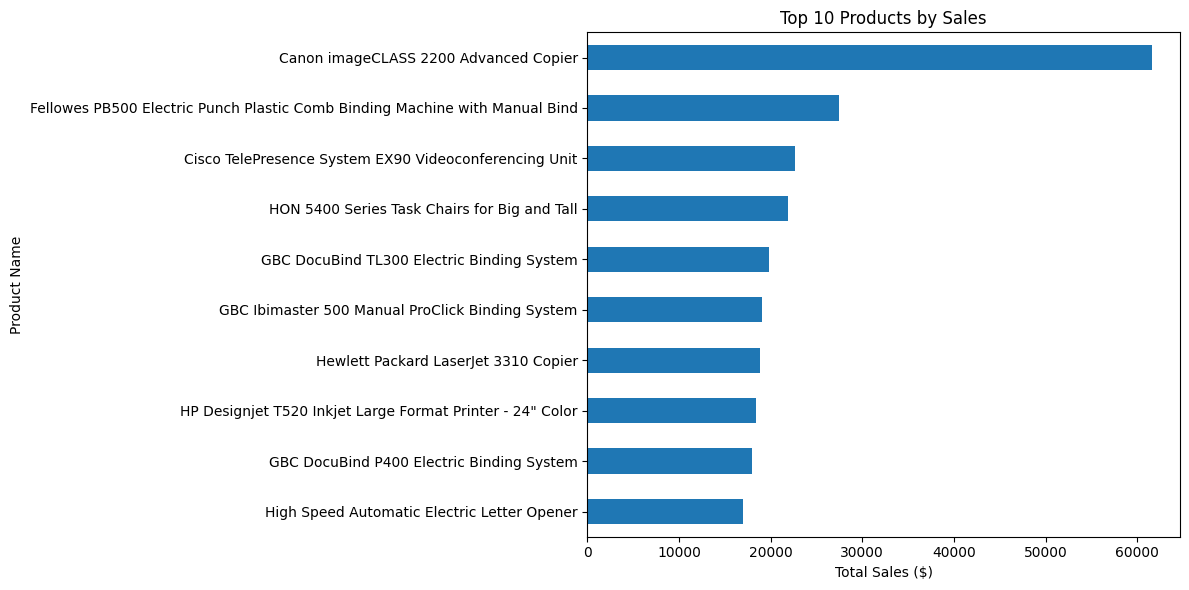

Top 10 Products by Sales:
Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Opener                                    17030.312
Name: Sales, dtype: float64


In [ ]:
# STEP 8: TOP 10 PRODUCTS BY SALES

top_products = (
    df_clean.groupby("Product Name")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))

top_products.sort_values().plot(kind="barh")

plt.title("Top 10 Products by Sales")
plt.xlabel("Total Sales ($)")
plt.ylabel("Product Name")
plt.tight_layout()
plt.show()

print("Top 10 Products by Sales:")
print(top_products)

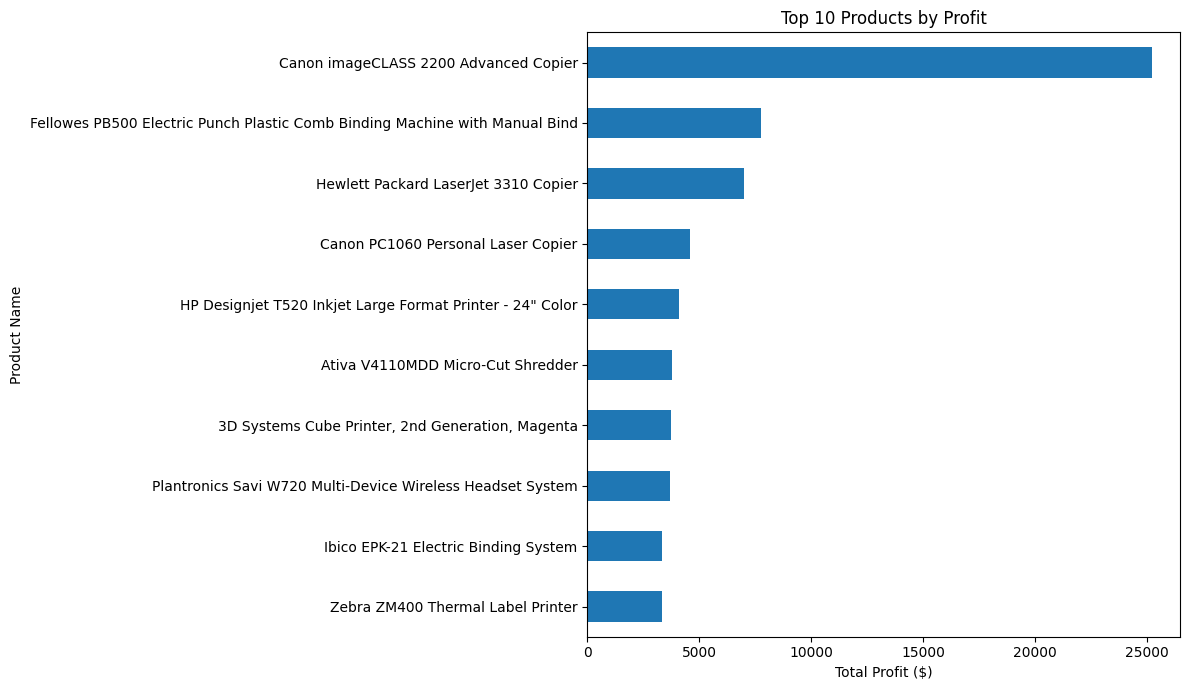

In [ ]:
# STEP 9: TOP 10 PRODUCTS BY PROFIT

import matplotlib.pyplot as plt

product_profit = df_clean.groupby("Product Name")["Profit"].sum()

top_10_profit = product_profit.nlargest(10)

plt.figure(figsize=(12, 7))
top_10_profit.sort_values().plot(kind="barh")

plt.title("Top 10 Products by Profit")
plt.xlabel("Total Profit ($)")
plt.ylabel("Product Name")
plt.tight_layout()
plt.show()
